# 03 — Pré-processamento e Pipeline

No notebook 02, a regressão linear com todas as colunas chegou a **MAE de 0,533** no teste (≈ US$ 53 mil de erro médio). No fim, encontramos quatro problemas:

1. **Escalas diferentes** impediam comparar os coeficientes.
2. **Underfitting**: o modelo era simples demais para os dados.
3. **Teto em 5,0** no alvo.
4. **Previsões impossíveis**: preços negativos e acima do teto.

Neste notebook vamos **preparar melhor os dados** para atacar esses problemas, sem trocar de modelo. Você vai aprender:

- O **conjunto de validação**, e por que não devemos tomar decisões olhando o teste
- **Padronização** de escalas (`StandardScaler`)
- **Vazamento de dados** (*data leakage*)
- **Pipeline**: encadear etapas de preparo e modelo
- **Engenharia de atributos**: criar colunas novas e mais úteis
- **Transformação logarítmica** para dados assimétricos
- **Pós-processamento** das previsões

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ferramentas novas deste notebook:
from sklearn.preprocessing import StandardScaler        # padroniza as escalas das colunas
from sklearn.preprocessing import FunctionTransformer   # transforma uma função nossa em "etapa" de pipeline
from sklearn.pipeline import Pipeline                   # encadeia etapas: preparo -> modelo

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

## 🎓 Conceito: conjunto de validação

No notebook 02, avaliamos cada modelo direto no **teste**. Com 3 modelos, tudo bem. Mas neste notebook vamos testar **muitas** ideias e escolher a melhor. Se escolhermos olhando o teste, aos poucos estaremos **ajustando nossas decisões ao teste**. Ele deixa de ser "dados nunca vistos", e a nota final fica otimista demais.

A solução é dividir os dados em **três** partes:

| Conjunto | Tamanho | Para quê |
|---|---|---|
| **Treino** | 60% | O modelo aprende com ele |
| **Validação** | 20% | **Nós** comparamos as ideias e escolhemos a melhor |
| **Teste** | 20% | Usado **uma única vez**, no final, para a nota oficial |

Pense assim: a validação é o **simulado**, e o teste é a **prova final**.

Para comparar de forma justa com o notebook 02, vamos separar **exatamente o mesmo teste** (mesmo `random_state=42`). Depois dividimos o restante em treino e validação.

In [2]:
# Passo 1: separa o teste, exatamente como no notebook 02 (20% dos dados).
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Passo 2: divide o que sobrou (80%) em treino e validação.
# 25% de 80% = 20% do total. Assim ficamos com 60% / 20% / 20%.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42
)

print(f"Treino:    {len(X_train):>6} linhas")
print(f"Validação: {len(X_val):>6} linhas")
print(f"Teste:     {len(X_test):>6} linhas  (fica guardado até o final!)")

Treino:     12384 linhas
Validação:   4128 linhas
Teste:       4128 linhas  (fica guardado até o final!)


**Conclusão:** 12.384 linhas para treinar, 4.128 para comparar ideias e 4.128 guardadas para a avaliação final. Daqui até a seção 11, **não vamos tocar em `X_test` nem em `y_test`**.

## 2. Ponto de partida: a regressão linear do notebook 02

In [3]:
# A mesma função de avaliação do notebook 02.
def avaliar(y_real, y_previsto):
    """Calcula MAE, RMSE e R² e devolve tudo num dicionário."""
    mae = mean_absolute_error(y_real, y_previsto)
    rmse = np.sqrt(mean_squared_error(y_real, y_previsto))
    r2 = r2_score(y_real, y_previsto)
    return {"MAE": round(float(mae), 3), "RMSE": round(float(rmse), 3), "R²": round(float(r2), 3)}


# Dicionário onde vamos guardar o resultado de cada ideia, na validação.
resultados_val = {}

modelo_base = LinearRegression()
modelo_base.fit(X_train, y_train)
resultados_val["Linear (notebook 02)"] = avaliar(y_val, modelo_base.predict(X_val))
resultados_val["Linear (notebook 02)"]

{'MAE': 0.533, 'RMSE': 0.728, 'R²': 0.614}

**Conclusão:** na validação, o modelo do notebook 02 tem MAE de **0,533**. Esse é o número que queremos baixar daqui em diante.

## 3. 🎓 Conceito: padronização (StandardScaler)

As colunas estão em escalas muito diferentes: `MedInc` vai de ~0,5 a 15, enquanto `Population` vai de 3 a ~35.000. A **padronização** coloca todas na mesma escala com a fórmula do **z-score**:

$$z = \frac{\text{valor} - \text{média}}{\text{desvio padrão}}$$

Depois disso, cada coluna fica com **média 0** e **desvio padrão 1**. O z-score diz **quantos desvios padrão** um valor está acima (+) ou abaixo (−) da média.

Vamos fazer a conta à mão primeiro, para entender o que acontece.

In [4]:
# Média e desvio padrão de MedInc, calculados SÓ no treino.
media = X_train["MedInc"].mean()
desvio = X_train["MedInc"].std(ddof=0)   # ddof=0 usa a mesma fórmula do StandardScaler
print(f"Média: {media:.3f}   Desvio padrão: {desvio:.3f}")

# Aplicando a fórmula nas 3 primeiras linhas:
for valor in X_train["MedInc"].iloc[:3]:
    z = (valor - media) / desvio
    print(f"renda {valor:6.3f}  ->  z = {z:+.2f}")

Média: 3.870   Desvio padrão: 1.888
renda  2.368  ->  z = -0.80
renda 10.136  ->  z = +3.32
renda  1.672  ->  z = -1.16


**Conclusão:** uma renda de 10,14 vira **z = +3,32**: ela está 3,3 desvios padrão acima da média, ou seja, é uma região muito rica. Já 1,67 vira **z = −1,16**, abaixo da média.

O `StandardScaler` faz exatamente essa conta, para todas as colunas de uma vez. Ele segue o mesmo padrão dos modelos, com um nome de método diferente para o segundo passo:
- **`.fit(X_train)`**: *aprende* a média e o desvio padrão de cada coluna (só no treino!).
- **`.transform(X)`**: *aplica* a fórmula usando o que aprendeu.

In [5]:
padronizador = StandardScaler()
padronizador.fit(X_train)   # aprende média e desvio de cada coluna

# .transform devolve um array do NumPy; colocamos de volta numa tabela para ler melhor.
X_train_pad = pd.DataFrame(padronizador.transform(X_train), columns=X_train.columns)

# Conferindo: agora todas as colunas têm média ≈ 0 e desvio ≈ 1.
X_train_pad.describe().loc[["mean", "std", "min", "max"]].round(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
mean,-0.000,0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.785,-2.188,-2.177,-1.983,-1.248,-0.331,-1.446,-2.379
max,5.895,1.857,27.150,28.508,30.023,84.347,2.960,2.628


**Conclusão:** todas as colunas agora têm média 0 e desvio 1. (O `-0.000` é só um número minúsculo, como −0,0000000000000002, arredondado.)

Repare nos máximos: `AveOccup` chega a **z ≈ 84**, ou seja, 84 desvios padrão acima da média! A padronização **não remove outliers**: ela só muda a escala. Vamos lidar com isso na seção 7.

In [6]:
# Treinamos a regressão linear com os dados padronizados.
modelo_pad = LinearRegression()
modelo_pad.fit(X_train_pad, y_train)

# A validação também precisa ser padronizada, com a média e o desvio do TREINO.
X_val_pad = pd.DataFrame(padronizador.transform(X_val), columns=X_val.columns)
avaliar(y_val, modelo_pad.predict(X_val_pad))

{'MAE': 0.533, 'RMSE': 0.728, 'R²': 0.614}

**Conclusão (surpresa!):** o erro é **exatamente igual** ao de antes (MAE 0,533). Isso acontece porque a regressão linear simplesmente "compensa" a escala ajustando os coeficientes: se uma coluna fica 1.000× menor, o coeficiente fica 1.000× maior, e as previsões não mudam.

Então para que padronizar? Por dois motivos:
1. **Interpretação:** agora os coeficientes ficam comparáveis (célula abaixo).
2. **Outros modelos precisam:** modelos como KNN, redes neurais e regressão com regularização (notebook 09) são muito sensíveis à escala. Padronizar é um hábito que evita problemas.

In [7]:
# Com as colunas na mesma escala, o coeficiente responde:
# "quanto o preço muda quando esta coluna sobe 1 desvio padrão?"
pd.Series(modelo_pad.coef_, index=X_train.columns).sort_values().round(3)

Latitude     -0.888
Longitude    -0.862
AveRooms     -0.280
AveOccup     -0.026
Population   -0.010
HouseAge      0.120
AveBedrms     0.312
MedInc        0.860
dtype: float64

**Conclusão:** agora dá para comparar. `MedInc` (+0,86), `Latitude` (−0,89) e `Longitude` (−0,86) são os efeitos mais fortes. A **localização pesa tanto quanto a renda**, algo que no notebook 02 não dava para ver, porque `Population` tinha coeficiente −0,000002 e parecia irrelevante só por causa da escala.

`AveRooms` (−0,28) e `AveBedrms` (+0,31) continuam com sinais opostos: a padronização não resolve a **multicolinearidade**.

## 4. 🎓 Conceito: vazamento de dados (data leakage)

Repare que fizemos `padronizador.fit(X_train)`, usando só o treino, e **não** `fit(X)` com todos os dados. Por quê?

Se calcularmos a média usando também a validação ou o teste, um pouco de informação desses dados "vaza" para o treino. O modelo passa a conhecer, mesmo que indiretamente, dados que deveriam ser **novos**. É como o professor dar uma dica da prova durante a aula: a nota sobe, mas não reflete o aprendizado real.

**Regra:** tudo que **aprende** algo com os dados (médias, desvios, mínimos, escolhas de colunas...) deve aprender **só com o treino**. Validação e teste apenas recebem a transformação.

Neste dataset grande e embaralhado, o efeito seria pequeno. Mas em dados reais (séries temporais, poucos exemplos, dados de pacientes repetidos) o vazamento pode transformar um modelo ruim num modelo que *parece* excelente.

Lembrar disso em cada etapa é trabalhoso e fácil de esquecer. É aí que entra o **Pipeline**.

## 🎓 Conceito: Pipeline

Um **Pipeline** é uma "linha de montagem": uma lista de etapas executadas em ordem. As primeiras transformam os dados, e a última é o modelo.

```
dados brutos  ->  [padronizar]  ->  [regressão linear]  ->  previsão
```

As vantagens:
- **`pipeline.fit(X_train, y_train)`** faz o `fit` de cada etapa **só com o treino**, automaticamente. Isso evita vazamento de dados.
- **`pipeline.predict(X_val)`** aplica as mesmas transformações e depois prevê. Não dá para esquecer nenhuma etapa.
- O preparo e o modelo viram **um único objeto**, fácil de salvar e reutilizar.

## 5. Nosso primeiro Pipeline

In [8]:
# Um Pipeline recebe uma lista de pares ("nome da etapa", objeto).
# Os nomes são escolhidos por nós e servem para acessar cada etapa depois.
pipeline_pad = Pipeline([
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])

# Um único .fit() treina tudo: o padronizador aprende com X_train e o modelo também.
pipeline_pad.fit(X_train, y_train)

# Um único .predict(): padroniza X_val com as médias do treino e depois prevê.
avaliar(y_val, pipeline_pad.predict(X_val))

{'MAE': 0.533, 'RMSE': 0.728, 'R²': 0.614}

**Conclusão:** mesmo resultado da seção 3 (MAE 0,533), mas agora com **2 linhas** em vez de 6, e sem risco de padronizar a validação com as médias erradas. A partir daqui, toda ideia nova vai virar uma etapa do pipeline.

In [9]:
# Acessando uma etapa pelo nome, como num dicionário:
pipeline_pad["padronizar"].mean_[:3]   # médias aprendidas (primeiras 3 colunas)

array([ 3.87008981, 28.58583656,  5.41183744])

## 🎓 Conceito: engenharia de atributos (feature engineering)

O modelo só enxerga as colunas que damos a ele. **Engenharia de atributos** é criar colunas novas a partir das existentes, colocando nosso conhecimento sobre o problema no formato que o modelo entende.

Isso é especialmente importante para modelos **lineares**: eles só conseguem somar colunas multiplicadas por coeficientes. Se a relação útil é uma **divisão** entre duas colunas, o modelo não consegue descobri-la sozinho.

No notebook 01 vimos duas colunas derivadas promissoras:
- `BedrmsPerRoom` = quartos ÷ cômodos (proporção de quartos)
- `RoomsPerPerson` = cômodos ÷ moradores (espaço por pessoa)

Para colocá-las no pipeline, escrevemos uma **função** e a embrulhamos com `FunctionTransformer`.

## 6. Atributos derivados

In [10]:
def criar_derivados(X):
    """Adiciona colunas de proporção que o modelo linear não consegue criar sozinho."""
    X = X.copy()   # copia para não alterar a tabela original
    X["BedrmsPerRoom"] = X["AveBedrms"] / X["AveRooms"]
    X["RoomsPerPerson"] = X["AveRooms"] / X["AveOccup"]
    return X


# Testando a função numa amostra de 3 linhas, só para ver as novas colunas:
criar_derivados(X_train.head(3))[["AveRooms", "AveBedrms", "AveOccup", "BedrmsPerRoom", "RoomsPerPerson"]]

,AveRooms,AveBedrms,AveOccup,BedrmsPerRoom,RoomsPerPerson
17244,3.922,1.019,3.754,0.260,1.045
8817,7.565,0.985,2.789,0.130,2.712
19686,3.908,0.917,2.540,0.235,1.539


In [11]:
pipeline_derivados = Pipeline([
    # FunctionTransformer transforma nossa função numa etapa do pipeline.
    # Ela não aprende nada com os dados (só divide colunas), então não há risco de vazamento.
    ("derivados", FunctionTransformer(criar_derivados)),
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])

pipeline_derivados.fit(X_train, y_train)
resultados_val["+ derivados"] = avaliar(y_val, pipeline_derivados.predict(X_val))
resultados_val["+ derivados"]

{'MAE': 0.492, 'RMSE': 0.682, 'R²': 0.662}

**Conclusão:** duas colunas novas baixaram o MAE de 0,533 para **0,492**, cerca de US$ 4 mil a menos de erro médio. É o efeito de dar ao modelo uma relação (a divisão) que ele não conseguia representar sozinho.

## 🎓 Conceito: assimetria e transformação logarítmica

No notebook 01, colunas como `AveOccup` e `Population` tinham **caudas longas à direita**: a maioria dos valores é pequena, mas alguns poucos são enormes. Chamamos isso de distribuição **assimétrica** (*skewed*).

Isso atrapalha o modelo linear: os poucos valores gigantes "puxam" a reta para eles e distorcem o coeficiente para todos os outros.

O **logaritmo** resolve isso porque "comprime" os valores grandes muito mais do que os pequenos:

| Valor | log(1 + valor) |
|---|---|
| 1 | 0,69 |
| 10 | 2,40 |
| 100 | 4,62 |
| 1.000 | 6,91 |

De 10 para 1.000 o valor cresceu 100×, mas o log só cresceu ~3×. Usamos `np.log1p(x)`, que calcula log(1 + x). O "+1" evita problemas com zero, porque log(0) não existe.

A **assimetria** (*skewness*) mede isso num número: perto de 0 é simétrico, e quanto maior, mais longa a cauda direita.

## 7. Transformação logarítmica

In [12]:
colunas_assimetricas = ["AveRooms", "AveBedrms", "Population", "AveOccup"]

# .skew() calcula a assimetria de cada coluna.
# pd.DataFrame({...}) monta uma tabela comparando antes e depois do log.
pd.DataFrame({
    "assimetria original": X_train[colunas_assimetricas].skew(),
    "assimetria após log": np.log1p(X_train[colunas_assimetricas]).skew(),
}).round(1)

,assimetria original,assimetria após log
AveRooms,9.2,1.2
AveBedrms,14.7,8.1
Population,5.8,-1.0
AveOccup,76.9,3.3


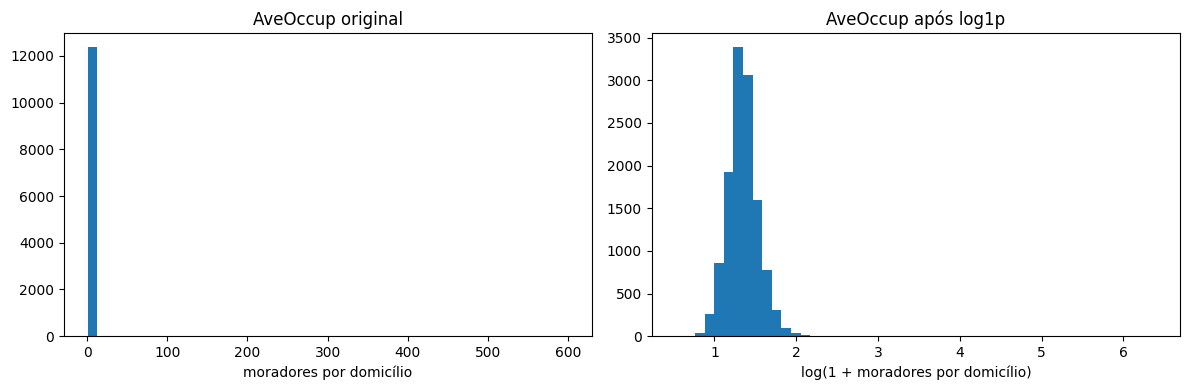

In [13]:
# Visualizando o efeito em AveOccup, a coluna mais assimétrica.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(X_train["AveOccup"], bins=50)
axes[0].set_title("AveOccup original")
axes[0].set_xlabel("moradores por domicílio")

axes[1].hist(np.log1p(X_train["AveOccup"]), bins=50)
axes[1].set_title("AveOccup após log1p")
axes[1].set_xlabel("log(1 + moradores por domicílio)")

plt.tight_layout()
plt.show()

**Conclusão:** a assimetria de `AveOccup` caiu de **76,9** para **3,3**. No gráfico da esquerda, quase todos os dados ficam espremidos numa única barra, porque alguns poucos blocos com mais de 1.000 "moradores por domicílio" esticam o eixo. Depois do log, a distribuição fica visível e bem mais equilibrada.

`AveBedrms` ainda fica assimétrica (8,1): o log ajuda, mas não faz milagre.

In [14]:
def aplicar_log(X):
    """Aplica log(1 + x) nas colunas com cauda longa à direita."""
    X = X.copy()
    # RoomsPerPerson também é assimétrica; o "if" só aplica se a coluna existir,
    # para a função funcionar com ou sem os atributos derivados.
    for coluna in colunas_assimetricas + ["RoomsPerPerson"]:
        if coluna in X.columns:
            X[coluna] = np.log1p(X[coluna])
    return X


# Testando o log sozinho e depois junto com os derivados.
pipeline_log = Pipeline([
    ("log", FunctionTransformer(aplicar_log)),
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])
pipeline_log.fit(X_train, y_train)
resultados_val["+ log"] = avaliar(y_val, pipeline_log.predict(X_val))

pipeline_deriv_log = Pipeline([
    ("derivados", FunctionTransformer(criar_derivados)),   # 1º cria as proporções
    ("log", FunctionTransformer(aplicar_log)),             # 2º comprime as caudas
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])
pipeline_deriv_log.fit(X_train, y_train)
resultados_val["+ derivados + log"] = avaliar(y_val, pipeline_deriv_log.predict(X_val))

print("Só log:          ", resultados_val["+ log"])
print("Derivados + log: ", resultados_val["+ derivados + log"])

Só log:           {'MAE': 0.493, 'RMSE': 0.676, 'R²': 0.667}
Derivados + log:  {'MAE': 0.484, 'RMSE': 0.67, 'R²': 0.673}


**Conclusão:** o log sozinho dá um ganho parecido com o dos derivados (MAE 0,493). Juntos, os dois chegam a **0,484**.

O ganho combinado é menor que a soma dos ganhos separados: as duas técnicas resolvem, em parte, o **mesmo** problema (as colunas de cômodos e moradores mal aproveitadas). É comum em ML que melhorias não se somem perfeitamente.

## 8. Um atributo geográfico

No notebook 01, o mapa mostrou que as casas mais caras ficam perto de **São Francisco** e de **Los Angeles**. Mas o modelo linear só consegue dizer "mais ao norte = mais barato" ou "mais ao leste = mais barato". Ele não consegue representar "**perto** de uma cidade grande = mais caro", porque essa relação **não é uma reta** na latitude e na longitude.

Vamos criar uma coluna com a **distância até a cidade grande mais próxima**. Usamos o teorema de Pitágoras sobre as coordenadas:

$$\text{distância} = \sqrt{(\text{lat} - \text{lat}_{\text{cidade}})^2 + (\text{lon} - \text{lon}_{\text{cidade}})^2}$$

É uma aproximação (a Terra não é plana!), medida em "graus", mas é suficiente para o modelo saber quem está perto e quem está longe.

In [15]:
# Coordenadas aproximadas (latitude, longitude) dos dois grandes centros.
SAO_FRANCISCO = (37.77, -122.42)
LOS_ANGELES = (34.05, -118.24)


def distancia(X, cidade):
    """Distância aproximada (em graus) de cada bloco até uma cidade."""
    lat, lon = cidade   # desempacota a tupla em duas variáveis
    return np.sqrt((X["Latitude"] - lat) ** 2 + (X["Longitude"] - lon) ** 2)   # ** é potência


def criar_dist_cidade(X):
    """Adiciona a distância até a cidade grande mais próxima (SF ou LA)."""
    X = X.copy()
    # np.minimum compara as duas distâncias linha a linha e fica com a menor.
    X["DistCidade"] = np.minimum(distancia(X, SAO_FRANCISCO), distancia(X, LOS_ANGELES))
    return X


pipeline_dist = Pipeline([
    ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])
pipeline_dist.fit(X_train, y_train)
resultados_val["+ distância"] = avaliar(y_val, pipeline_dist.predict(X_val))

pipeline_completo = Pipeline([
    ("derivados", FunctionTransformer(criar_derivados)),
    ("log", FunctionTransformer(aplicar_log)),
    ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
    ("padronizar", StandardScaler()),
    ("modelo", LinearRegression()),
])
pipeline_completo.fit(X_train, y_train)
resultados_val["+ derivados + log + distância"] = avaliar(y_val, pipeline_completo.predict(X_val))

print("Só distância: ", resultados_val["+ distância"])
print("Tudo junto:   ", resultados_val["+ derivados + log + distância"])

Só distância:  {'MAE': 0.527, 'RMSE': 0.718, 'R²': 0.625}
Tudo junto:    {'MAE': 0.477, 'RMSE': 0.658, 'R²': 0.685}


**Conclusão:** sozinha, a distância ajuda **pouco** (0,533 → 0,527). Junto com as outras melhorias, ela leva o MAE a **0,477**, o melhor até agora.

Duas lições aqui:
1. **Nem toda boa ideia gera um ganho grande.** A distância "em linha reta" até só duas cidades é uma simplificação: há outras regiões caras (San Diego, a costa inteira).
2. É por isso que **sempre medimos**: a intuição sugere ideias, mas quem decide é o resultado na validação.

Mesmo assim, o modelo linear continua limitado para relações geográficas. Os modelos de árvore do notebook 04 lidam com isso de forma muito mais natural.

## 9. Comparando todas as ideias (validação)

In [16]:
# pd.DataFrame(dicionário).T: cada chave vira uma linha e cada métrica, uma coluna.
comparacao = pd.DataFrame(resultados_val).T
comparacao.sort_values("MAE")

,MAE,RMSE,R²
+ derivados + log + distância,0.477,0.658,0.685
+ derivados + log,0.484,0.670,0.673
+ derivados,0.492,0.682,0.662
+ log,0.493,0.676,0.667
+ distância,0.527,0.718,0.625
Linear (notebook 02),0.533,0.728,0.614


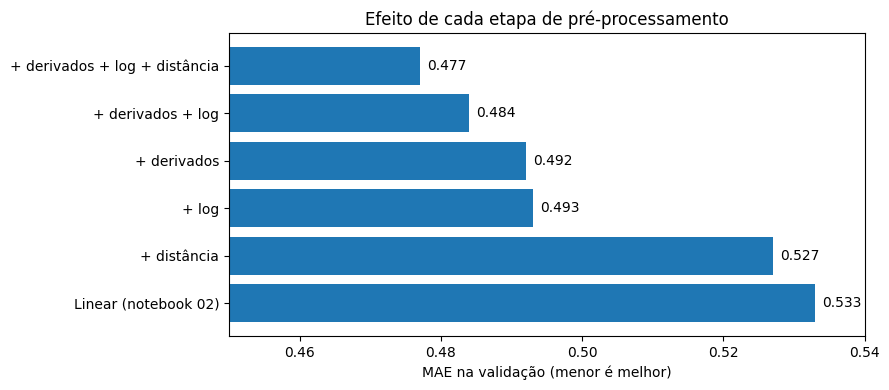

In [17]:
# Gráfico de barras horizontais com o MAE de cada ideia.
ordenado = comparacao["MAE"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ordenado.index, ordenado.values)   # barh = barras horizontais
ax.set_xlim(0.45, 0.54)                     # "zoom" no eixo para as diferenças ficarem visíveis
ax.set_xlabel("MAE na validação (menor é melhor)")
ax.set_title("Efeito de cada etapa de pré-processamento")

# Escreve o valor ao lado de cada barra.
for i, valor in enumerate(ordenado.values):   # enumerate dá a posição (i) e o valor
    ax.text(valor + 0.001, i, f"{valor:.3f}", va="center")

plt.tight_layout()
plt.show()

**Conclusão:** cada etapa contribui, e o pipeline completo reduziu o MAE de 0,533 para **0,477** (−10%). O R² subiu de 0,61 para 0,68.

⚠️ Atenção ao `ax.set_xlim(0.45, ...)`: o eixo **não começa no zero**, então as diferenças parecem maiores do que são. Isso é útil para enxergar detalhes, mas sempre confira os números ao ler um gráfico assim.

## 10. E o teto em 5,0?

Temos duas estratégias principais:

**Estratégia A: remover do treino as casas no teto.** A ideia é que o valor "5,0" delas é falso (o real é maior), e isso confunde o modelo.

⚠️ Mas só podemos remover do **treino**. Na validação, no teste e no mundo real, essas casas continuam existindo, e o modelo terá de prever para elas.

**Estratégia B: manter tudo e só corrigir as previsões impossíveis.** Isso é um **pós-processamento**: depois de prever, limitamos as previsões ao intervalo que existe nos dados.

Vamos testar as duas.

In [18]:
# --- Estratégia A: treinar sem as casas no teto ---
fora_do_teto = y_train < 5   # filtro True/False

# sklearn.base.clone cria uma cópia "zerada" (não treinada) do pipeline,
# com as mesmas etapas. Assim não estragamos o pipeline_completo já treinado.
from sklearn.base import clone
pipeline_sem_teto = clone(pipeline_completo)
pipeline_sem_teto.fit(X_train[fora_do_teto], y_train[fora_do_teto])

prev_com_teto = pipeline_completo.predict(X_val)   # treinado com todas as linhas
prev_sem_teto = pipeline_sem_teto.predict(X_val)   # treinado sem as casas no teto

# Avaliando separadamente: todas as casas, só as fora do teto e só as do teto.
val_teto = y_val >= 5
tabela_teto = pd.DataFrame({
    "MAE geral": [mean_absolute_error(y_val, p) for p in [prev_com_teto, prev_sem_teto]],
    "MAE casas normais": [mean_absolute_error(y_val[~val_teto], p[~val_teto]) for p in [prev_com_teto, prev_sem_teto]],
    "MAE casas no teto": [mean_absolute_error(y_val[val_teto], p[val_teto]) for p in [prev_com_teto, prev_sem_teto]],
}, index=["Treino com teto", "Treino sem teto"])
tabela_teto.round(3)

,MAE geral,MAE casas normais,MAE casas no teto
Treino com teto,0.477,0.440,1.175
Treino sem teto,0.471,0.427,1.278


*Sobre o código:* `[... for p in [a, b]]` é uma **list comprehension**, uma forma compacta de criar uma lista repetindo uma conta para cada item. Equivale a um `for` com `.append()`.

**Conclusão:** remover as casas no teto melhora um pouco o geral (0,477 → 0,471) e as casas normais, mas **piora as casas no teto** (1,17 → 1,28). Faz sentido: o modelo nunca viu casas caras no treino, então erra ainda mais nelas.

O ganho é pequeno e penaliza justamente as casas mais caras. Vamos **manter todas as linhas** e ficar com o modelo mais honesto. Essa é uma decisão de projeto: se o objetivo fosse só imóveis abaixo de US$ 500 mil, a estratégia A seria a melhor escolha.

Agora a estratégia B.

In [19]:
# --- Estratégia B: limitar as previsões ---
print("Previsões negativas:   ", (prev_com_teto < 0).sum())
print("Previsões acima de 5.0:", (prev_com_teto > 5).sum())

# O menor e o maior valor do alvo no TREINO definem o intervalo possível.
# (Usar o treino, e não a validação, evita vazamento de dados!)
MINIMO, MAXIMO = y_train.min(), y_train.max()
print(f"Intervalo do treino: {MINIMO:.2f} a {MAXIMO:.2f}")


def prever_limitado(pipeline, X):
    """Prevê e corta valores fora do intervalo visto no treino."""
    # np.clip troca tudo abaixo de MINIMO por MINIMO e tudo acima de MAXIMO por MAXIMO.
    return np.clip(pipeline.predict(X), MINIMO, MAXIMO)


resultados_val["Completo + limitar previsões"] = avaliar(y_val, prever_limitado(pipeline_completo, X_val))
resultados_val["Completo + limitar previsões"]

Previsões negativas:    26
Previsões acima de 5.0: 43
Intervalo do treino: 0.15 a 5.00


{'MAE': 0.465, 'RMSE': 0.638, 'R²': 0.704}

**Conclusão:** havia 26 previsões negativas e 43 acima de 5,0. Cortando-as ao intervalo possível, o MAE caiu de 0,477 para **0,465**. É uma melhoria "de graça", porque uma previsão de preço negativo é sempre mais errada do que o mínimo possível.

Repare que limitar **não ensina nada novo ao modelo**: é uma regra aplicada depois. Os modelos de árvore (notebook 04) nunca preveem fora do intervalo do treino, então esse problema some naturalmente.

## 11. Avaliação final no teste

Chegou a hora da **prova final**. Escolhemos nossa melhor abordagem **usando só a validação**:

> Pipeline completo (derivados + log + distância + padronização + regressão linear) com previsões limitadas.

Agora fazemos duas coisas:
1. **Retreinamos com treino + validação** (`X_train_full`). A validação já cumpriu seu papel de nos ajudar a escolher. Agora usamos esses dados para o modelo aprender mais.
2. **Avaliamos no teste, uma única vez.** Nada de voltar e ajustar depois de ver o resultado!

In [20]:
# Modelo do notebook 02, retreinado nos mesmos dados para uma comparação justa.
modelo_02 = LinearRegression()
modelo_02.fit(X_train_full, y_train_full)

# Nosso pipeline final: cópia zerada do pipeline completo, treinada com treino + validação.
pipeline_final = clone(pipeline_completo)
pipeline_final.fit(X_train_full, y_train_full)

# Atualizamos o intervalo para usar todos os dados de treino disponíveis.
MINIMO, MAXIMO = y_train_full.min(), y_train_full.max()

resultado_teste = pd.DataFrame({
    "Notebook 02 (linear simples)": avaliar(y_test, modelo_02.predict(X_test)),
    "Notebook 03 (pipeline final)": avaliar(y_test, prever_limitado(pipeline_final, X_test)),
}).T
resultado_teste

,MAE,RMSE,R²
Notebook 02 (linear simples),0.533,0.746,0.576
Notebook 03 (pipeline final),0.464,0.644,0.684


In [21]:
# Quanto melhorou, em porcentagem e em dólares?
mae_02 = resultado_teste.loc["Notebook 02 (linear simples)", "MAE"]
mae_03 = resultado_teste.loc["Notebook 03 (pipeline final)", "MAE"]

print(f"Redução do erro médio: {(mae_02 - mae_03) / mae_02:.1%}")
print(f"Em dólares: de US$ {mae_02 * 100_000:,.0f} para US$ {mae_03 * 100_000:,.0f}")

Redução do erro médio: 12.9%
Em dólares: de US$ 53,300 para US$ 46,400


**Conclusão:** no teste, com dados que nunca influenciaram nenhuma decisão, o erro médio caiu de **US$ 53.300 para US$ 46.400** (−13%), e o R² subiu de **0,58 para 0,68**. **Sem trocar de modelo**: continua sendo uma regressão linear. Toda a melhoria veio de preparar melhor os dados.

O resultado no teste ficou próximo do da validação (MAE 0,465). Isso indica que nossas escolhas **generalizam** e não foram só sorte na validação.

In [22]:
# Por curiosidade: os coeficientes do modelo final (já comparáveis, graças à padronização).
# pipeline_final["modelo"] acessa a etapa chamada "modelo".
modelo_final = pipeline_final["modelo"]

# Para descobrir os nomes das colunas que chegam ao modelo, passamos uma linha pelas
# etapas que criam colunas. Fatiar um pipeline funciona como fatiar uma lista:
# [:-2] = todas as etapas menos as 2 últimas (padronizar e modelo).
# (Depois do StandardScaler, os dados viram um array sem nomes de colunas.)
nomes = pipeline_final[:-2].transform(X_train_full.head(1)).columns
pd.Series(modelo_final.coef_, index=nomes).sort_values().round(3)

Latitude         -0.759
Longitude        -0.709
AveRooms         -0.204
DistCidade       -0.157
AveBedrms        -0.127
Population        0.047
HouseAge          0.100
AveOccup          0.140
BedrmsPerRoom     0.271
RoomsPerPerson    0.665
MedInc            0.700
dtype: float64

**Conclusão:** `RoomsPerPerson` (espaço por morador), uma coluna que **nós criamos**, virou um dos coeficientes mais fortes, junto com `MedInc` e a localização. Esse é o poder da engenharia de atributos. `DistCidade` tem coeficiente negativo: quanto **mais longe** de SF/LA, **mais barato**, como esperávamos.

Ainda há pares com sinais opostos, sinal de multicolinearidade (colunas como `AveRooms` e `RoomsPerPerson` carregam informação parecida). Por isso continuamos interpretando os coeficientes com cuidado.

## 12. Resumo e próximos passos

**Conceitos que você aprendeu**
- **Validação**: o "simulado" onde tomamos decisões, guardando o teste para a "prova final".
- **Padronização (z-score)**: não muda o resultado da regressão linear, mas permite comparar coeficientes e é essencial para outros modelos.
- **Vazamento de dados**: tudo que aprende algo com os dados aprende **só com o treino**.
- **Pipeline**: encadeia preparo e modelo num único objeto e evita vazamento.
- **Engenharia de atributos**: proporções e distâncias que o modelo linear não cria sozinho.
- **Transformação logarítmica**: comprime caudas longas.
- **Pós-processamento**: limitar previsões ao intervalo possível.
- **Retreinar com treino + validação** antes da avaliação final.

**Python novo:** `FunctionTransformer` com funções próprias, `clone`, `np.clip`, `np.minimum`, `enumerate`, list comprehension e tuplas.

**Evolução no teste**

| Notebook | Modelo | MAE | R² |
|---|---|---|---|
| 02 | Baseline (média) | 0,906 | 0,00 |
| 02 | Linear (todas as colunas) | 0,533 | 0,58 |
| 03 | Pipeline final (mesma regressão linear!) | 0,464 | 0,68 |

**Problemas que continuam**
- O modelo ainda é **linear**: relações como "perto do litoral = caro" só entram se nós as criarmos à mão.
- O **teto** continua limitando o que dá para aprender sobre casas caras.

**Próximo notebook (04):** árvores de decisão e random forest. São modelos que **descobrem sozinhos** relações não lineares, não preveem fora do intervalo do treino e não precisam de padronização. Vamos ver se eles superam todo o nosso trabalho manual!